In [3]:
import pandas as pd
import numpy as np

In [4]:
df= pd.read_csv("/content/titanic.csv")

In [5]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [6]:
# even =((n/2)+((n/2)+1))/2
# odd = ((n/2)+1)

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
df['Age'].describe()

,Age
count,332.000000
mean,30.272590
std,14.181209
min,0.170000
25%,21.000000
50%,27.000000
75%,39.000000
max,76.000000


<Axes: xlabel='Age'>

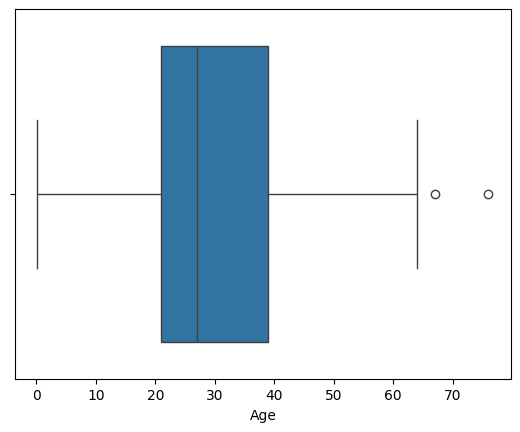

In [9]:
sns.boxplot(x=df['Age'])

In [10]:
# finding the IQR

percentile25=df['Age'].quantile(0.25)
percentile75=df['Age'].quantile(0.75)


In [11]:
percentile25

np.float64(21.0)

In [12]:
percentile75

np.float64(39.0)

In [13]:
IQR = percentile75 - percentile25
IQR

np.float64(18.0)

In [14]:
upper_limit = percentile75 + 1.5*IQR
upper_limit

np.float64(66.0)

In [15]:
lower_limit = percentile25 - 1.5*IQR
lower_limit

np.float64(-6.0)

In [16]:
# finding our Outliers

In [17]:
df[df['Age']>upper_limit]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
81,973,0,1,"Straus, Mr. Isidor",male,67.0,1,0,PC 17483,221.7792,C55 C57,S
96,988,1,1,"Cavendish, Mrs. Tyrell William (Julia Florence...",female,76.0,1,0,19877,78.8500,C46,S


In [18]:
df[df['Age']<lower_limit]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked


In [19]:
# Trimming---> 4(lower).....1, upper(25).....(50) ----> here 1,50 are outliers --->
# lower(4) <------> upper(25) mid data


# capping ----> 4(lower)....1, upper(25).....(50) ----> capping lower point lowest point(1)
# upper point upper point(50) ---> Range expand ----> outliers remove

In [20]:
# Trimming (outliers removing technique 1)

In [21]:
newdf = df[df['Age']<upper_limit]

In [22]:
# newdf

In [23]:
# comparision

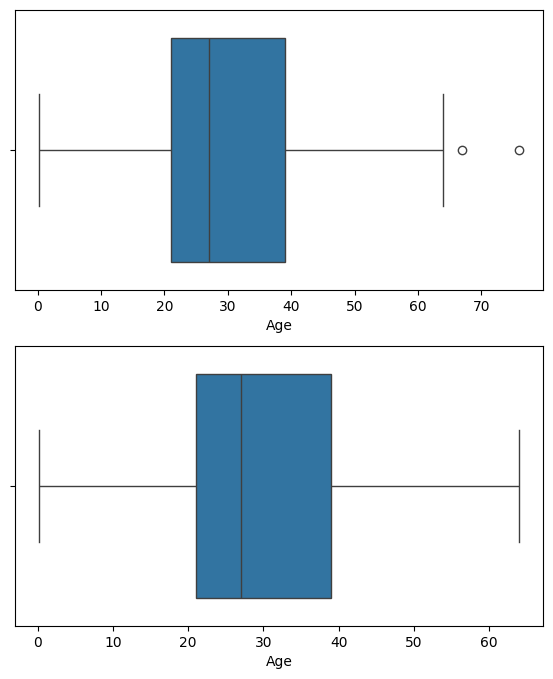

In [33]:
plt.figure(figsize=(15,8))

plt.subplot(222)
sns.boxplot(x=df['Age'])

plt.subplot(224)
sns.boxplot(x=newdf['Age'])
plt.show()

In [25]:
# capping (outlier removing technique 2)

In [26]:
new_df_cap= df.copy()

In [27]:
# min = 5 , max 15
# min 4 , 3, 1
# max= 20, 30, 50

#updated_min_value= 1
#updated_max_value=50

In [28]:
new_df_cap['Age']=np.where(
    new_df_cap['Age']>upper_limit, upper_limit,

    np.where(new_df_cap['Age']<lower_limit, lower_limit,
    new_df_cap['Age'])

)

In [29]:
new_df_cap

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
413,1305,0,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,0,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,0,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [30]:
new_df_cap.shape

(418, 12)

In [31]:
# comparision

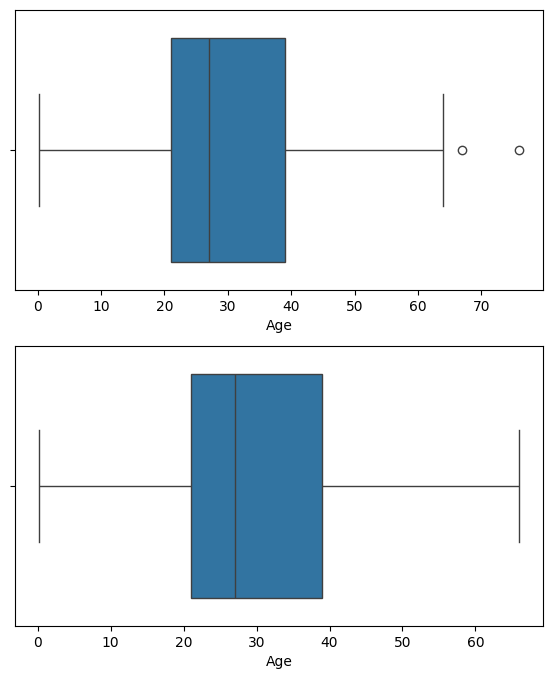

In [32]:
plt.figure(figsize=(15,8))

plt.subplot(222)
sns.boxplot(x=df['Age'])

plt.subplot(224)
sns.boxplot(x=new_df_cap['Age'])
plt.show()